In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [23]:
df=pd.read_csv("sample_data/credit_risk_dataset.csv")

In [24]:
#EDA- looking at data and understanding it without touching it
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [25]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [26]:
df['loan_status'].unique()
#we have a classification problem

array([1, 0])

In [27]:
df['loan_status'].value_counts()  #class imbalance

,count
loan_status,
0,25473
1,7108


<Axes: xlabel='loan_status', ylabel='count'>

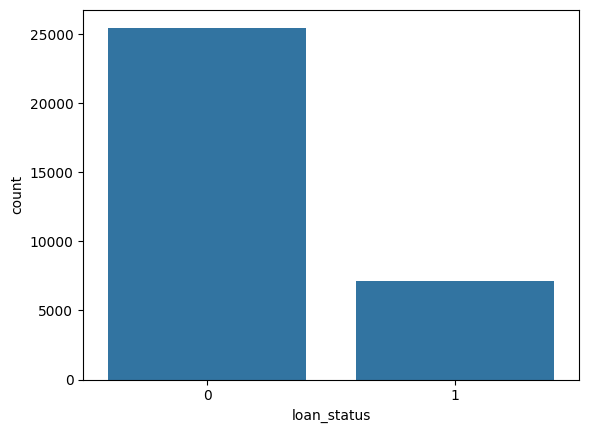

In [28]:
sns.countplot(df,x='loan_status')

In [29]:
#checking outliers n correlation
df['person_age'].describe()

,person_age
count,32581.000000
mean,27.734600
std,6.348078
min,20.000000
25%,23.000000
50%,26.000000
75%,30.000000
max,144.000000


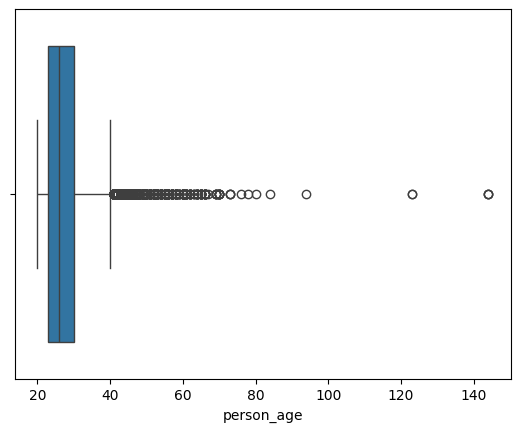

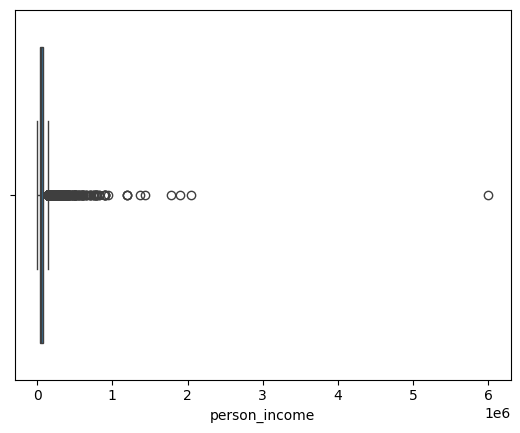

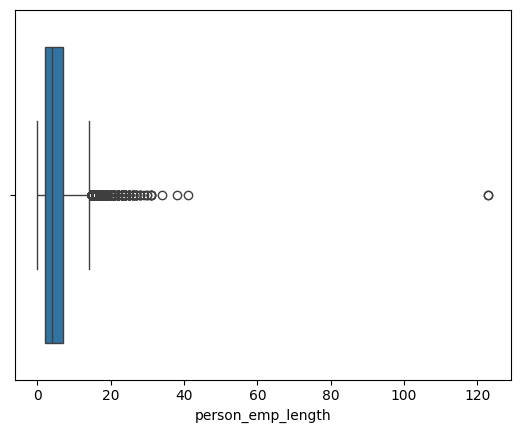

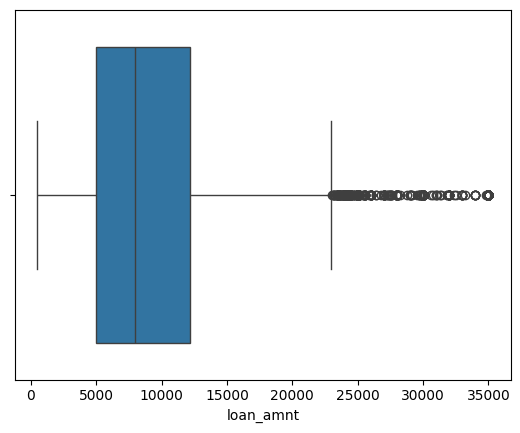

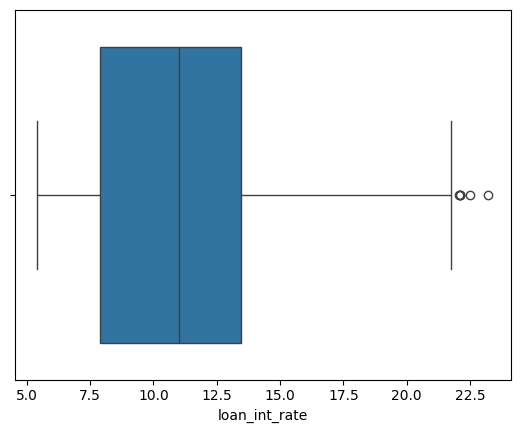

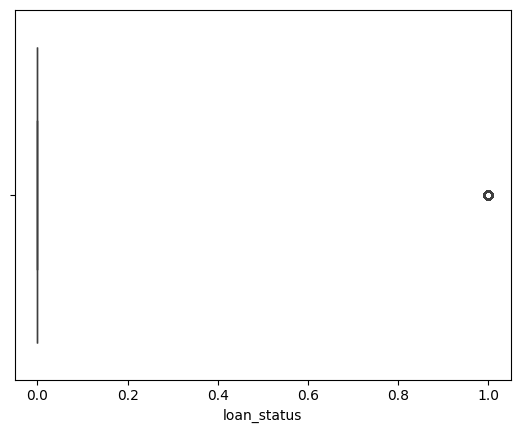

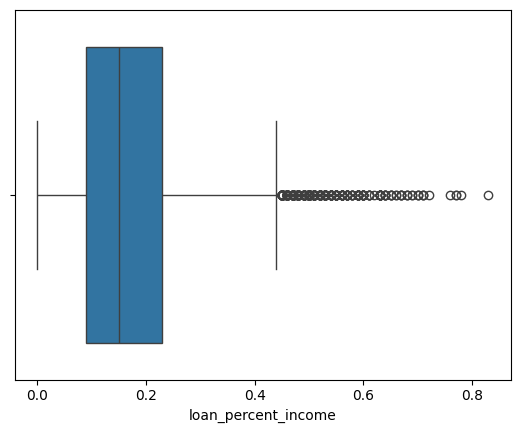

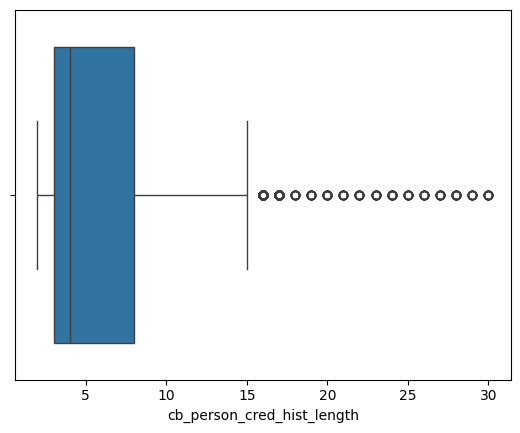

In [30]:
numerical_cols=df.select_dtypes(include='number').columns
for i in numerical_cols:
  sns.boxplot(x=df[i])
  plt.show()

In [31]:
df[df['person_emp_length'] > 60]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
210,21,192000,MORTGAGE,123.0,VENTURE,A,20000,6.54,0,0.10,N,4


In [32]:
df[df['person_age'] > 100]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,NaN,0,0.26,N,4
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25


<Axes: >

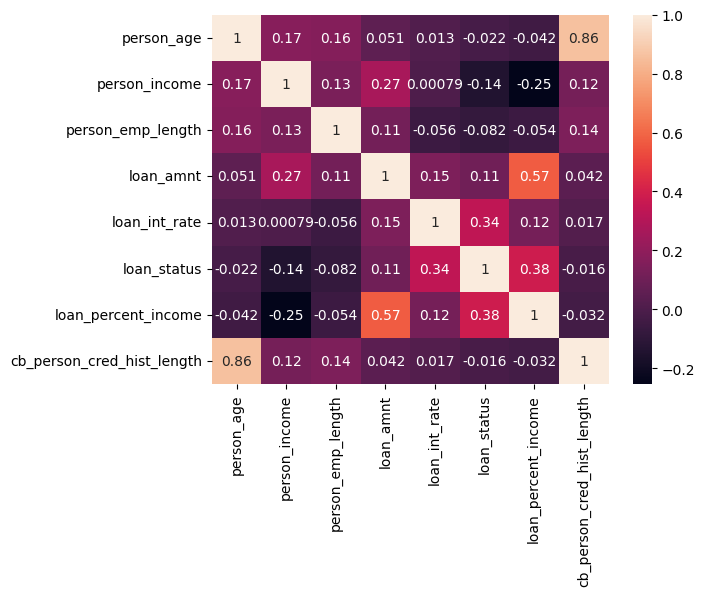

In [33]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [34]:
#handling outliers is very very imp-otherwise model drifts

In [35]:
df.duplicated().sum()

np.int64(165)

In [36]:
df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


In [37]:
df['loan_intent'].value_counts()

,count
loan_intent,
EDUCATION,6453
MEDICAL,6071
VENTURE,5719
PERSONAL,5521
DEBTCONSOLIDATION,5212
HOMEIMPROVEMENT,3605


In [38]:
df['loan_grade'].value_counts()

,count
loan_grade,
A,10777
B,10451
C,6458
D,3626
E,964
F,241
G,64


In [39]:
#now making actual changes to data after seeing problems
df_copy=df.copy()
df_copy.drop_duplicates(inplace=True)

In [40]:
df_copy=df_copy[(df_copy['person_age'] >= 18) & (df_copy['person_age'] <= 100)]

In [41]:
df_copy

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


In [42]:
df_copy=df_copy[df_copy['person_emp_length'] <= 60 ]

In [43]:
df_copy=df_copy[df_copy['person_emp_length'] <= df_copy['person_age']]

In [44]:
df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


In [45]:
df_copy[df_copy['loan_amnt'] <= 0]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length


In [46]:
X=df_copy.drop('loan_status',axis=1)
y=df_copy['loan_status']

In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [48]:
numerical_cols=['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
categorical_cols=['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file']

In [49]:
#we handle class imbalance using smote and class weights
#w r using class weights- tells model to focus same on the class whose freq is less
#logistic reg has this ibuilt
#so we r using this as baseline model as xgboost that we r mainly going to use doesnt have class weights

In [50]:
y_train.value_counts()

,count
loan_status,
0,19772
1,5445


In [51]:
neg , pos =np.bincount(y_train)

In [52]:
neg

np.int64(19772)

In [53]:
pos

np.int64(5445)

In [54]:
scale_weights=neg/pos
#now xg boost will be given this

In [55]:
df_copy

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
5,21,9900,OWN,2.0,VENTURE,A,2500,7.14,1,0.25,N,2
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


In [90]:
#lOGISTIC reg- impute + scaling , impute + one hot encoding
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.linear_model import LogisticRegression

preprocessor_lr = ColumnTransformer(
    transformers=[
        ('num',
         Pipeline([
             ('imputer', SimpleImputer(strategy='mean')),
             ('scaler', StandardScaler())
         ]),
         numerical_cols),
        ('cat',
         Pipeline([
             ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
             ('onehot', OneHotEncoder(handle_unknown='ignore'))
         ]),
         categorical_cols)
    ]
)

In [91]:

#XGBOOST pipeline  ... only impute
#scaling not required for xgboost
#, impute+onehot


preprocessor_xg= ColumnTransformer(
    transformers=[
        ('num',
         Pipeline([
             ('imputer', SimpleImputer(strategy='mean'))
         ]),
         numerical_cols),
        ('cat',
         Pipeline([
             ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
             ('onehot', OneHotEncoder(handle_unknown='ignore'))
         ]),
         categorical_cols)
    ]
)


In [92]:
from sklearn.model_selection import StratifiedKFold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'roc_auc': 'roc_auc',
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}


In [93]:
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline=Pipeline(
    [('preprocessor',preprocessor_lr),
     ('classifier',LogisticRegression(max_iter=1000,class_weight='balanced',random_state=42))]
)
lr_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [60]:
from xgboost import XGBClassifier
xgb_cv_pipeline=Pipeline(
    [('preprocessor',preprocessor_xg),
     ('classifier',XGBClassifier(n_estimators=300,max_depth=5,learning_rate=0.1,scale_pos_weight=scale_weights,random_state=42))]
)
xgb_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   O...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [61]:
from sklearn.model_selection import cross_validate

for cv_name, pipe in [("Logistic Regression", lr_cv_pipeline),
                      ("XGBoost", xgb_cv_pipeline)]:
    cv_results = cross_validate(
        pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1
    )
    print(cv_name)
    print(f"{cv_name} cross validation scores:")
    print(f"ROC AUC: {cv_results['test_roc_auc'].mean():.4f}")
    print(f"Accuracy: {cv_results['test_accuracy'].mean():.4f}")
    print(f"Precision: {cv_results['test_precision'].mean():.4f}")
    print(f"Recall: {cv_results['test_recall'].mean():.4f}")
    print(f"F1 Score: {cv_results['test_f1'].mean():.4f}")
    print()


Logistic Regression
Logistic Regression cross validation scores:
ROC AUC: 0.8705
Accuracy: 0.8116
Precision: 0.5449
Recall: 0.7785
F1 Score: 0.6410

XGBoost
XGBoost cross validation scores:
ROC AUC: 0.9476
Accuracy: 0.9183
Precision: 0.8199
Recall: 0.7972
F1 Score: 0.8082



#Lets create a helper that calculates all evaluation metrics

In [62]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve
)

def evaluate_model(model_name, model, X_test, y_test):

    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)[:, 1]

    # Metrics
    acc_val = accuracy_score(y_test, y_pred)
    prec_val = precision_score(y_test, y_pred)
    rec_val = recall_score(y_test, y_pred)
    f1_val = f1_score(y_test, y_pred)
    roc_auc_val = roc_auc_score(y_test, y_pred_proba)
    cm_val = confusion_matrix(y_test, y_pred)
    cr_val = classification_report(y_test, y_pred)

    print(f"{model_name} Metrics:")
    print(f"Accuracy: {acc_val:.4f}")
    print(f"Precision: {prec_val:.4f}")
    print(f"Recall: {rec_val:.4f}")
    print(f"F1 Score: {f1_val:.4f}")
    print(f"ROC AUC: {roc_auc_val:.4f}")

    # Precision-Recall Curve
    precision, recall, thresholds = precision_recall_curve(
        y_test, y_pred_proba
    )

    plt.figure(figsize=(7, 5))
    plt.plot(recall, precision)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"{model_name} - Precision Recall Curve")
    plt.grid(alpha=0.3)
    plt.show()

    # ROC Curve
    fpr, tpr, thresholds_roc = roc_curve(y_test, y_pred_proba)

    plt.figure(figsize=(7, 5))
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc_val:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{model_name} - ROC Curve")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    # Confusion Matrix
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm_val, annot=True, fmt="d", cmap="Blues")
    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted Labels")
    plt.ylabel("True Labels")
    plt.show()

    # Classification Report
    print(f"Classification Report:\n{cr_val}")

    return {
        "Accuracy": acc_val,
        "Precision": prec_val,
        "Recall": rec_val,
        "F1 Score": f1_val,
        "ROC AUC": roc_auc_val,
        "Confusion Matrix": cm_val
    }

In [63]:
#Bseline Model
baseline_model=Pipeline(
    [('preprocessor',preprocessor_lr),
     ('classifier',LogisticRegression(class_weight='balanced'))]
)
baseline_model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier', LogisticRegression(class_weight='balanced'))])

Baseline Model Metrics:
Accuracy: 0.8193
Precision: 0.5580
Recall: 0.7871
F1 Score: 0.6531
ROC AUC: 0.8751


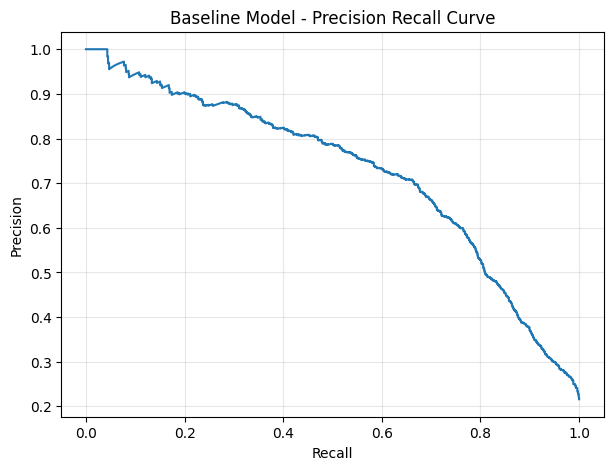

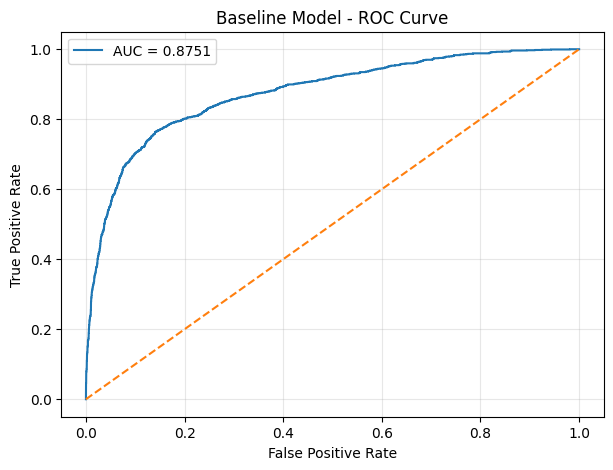

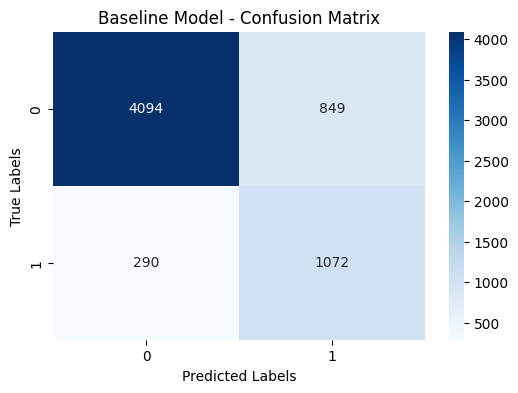

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



{'Accuracy': 0.8193497224425059,
 'Precision': 0.5580426861009891,
 'Recall': 0.7870778267254038,
 'F1 Score': 0.6530612244897959,
 'ROC AUC': np.float64(0.8751205742527961),
 'Confusion Matrix': array([[4094,  849],
        [ 290, 1072]])}

In [64]:
# Evaluating the Baseline Model
evaluate_model("Baseline Model", baseline_model, X_test, y_test)

In [65]:
#hyperamter tuning on xg boost model
xg_model=Pipeline([
    ('preprocessor',preprocessor_xg),
    ('classifier',XGBClassifier(scale_pos_weight=scale_weights,random_state=42))
])

In [66]:
#hyperparameter tuning is done here using randomizedsearch cv
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform #due to stats , the below lists becomes iterable(distribution) whihc is needed

# Using scipy.stats distributions so RandomizedSearchCV can sample from them
param_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth": randint(3, 9),
    "classifier__learning_rate": uniform(0.01, 0.49), # range [0.01, 0.01 + 0.49]
    "classifier__subsample": uniform(0.4, 0.2),       # range [0.4, 0.4 + 0.2]        sampling of rows (shuffling)
    "classifier__colsample_bytree": uniform(0.4, 0.2), # range [0.4, 0.4 + 0.2]   col sampling (shuffling)
    "classifier__min_child_weight": randint(1, 10),
    "classifier__gamma": uniform(0, 10)               # controls splits
}

#lower gamma - more splits more tree depth - complex tree - higher overfitting risk
#higher gamma - less splits - simple tree - low overfitting risk

In [67]:
random_search=RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=50,
    cv=cv,
    scoring=scoring,
    refit='roc_auc', # Specifies which metric to use to find the best model configuration
    n_jobs=-1,
    verbose=1,
    random_state=42
)

random_search.fit(X_train,y_train)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer())]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length']),
                                                                              ('cat',
                                                                               Pipeli...
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7898cdc32660>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7898cc7a60d0>},
                   random_state=42, refit='roc_auc',
                   scoring={'accuracy': 'accuracy', 'f1': 'f1',
                            'precision': 'precision', 'recall': 'recall',
                            'roc_auc': 'roc_auc'},
                   verbose=1)

In [68]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

# 1. Pipelines
rf_model = Pipeline([
    ('preprocessor', preprocessor_lr), # Random Forest can use the scaled features preprocessor
    ('classifier', RandomForestClassifier(class_weight='balanced', random_state=42))
])

ada_model = Pipeline([
    ('preprocessor', preprocessor_lr), # AdaBoost can use scaled features preprocessor
    ('classifier', AdaBoostClassifier(random_state=42))
])

# 2. Parameter Grids
rf_param_grid = {
    "classifier__n_estimators": randint(100, 500),
    "classifier__max_depth": randint(3, 12),
    "classifier__min_samples_split": randint(2, 11),
    "classifier__min_samples_leaf": randint(1, 10)
}

ada_param_grid = {
    "classifier__n_estimators": randint(50, 300),
    "classifier__learning_rate": uniform(0.01, 1.0)
}

# 3. Randomized Search Setup
rf_random_search = RandomizedSearchCV(
    rf_model,
    rf_param_grid,
    n_iter=50, # Lower iter to run reasonably fast
    cv=cv,
    scoring=scoring,
    refit='roc_auc',
    n_jobs=-1,
    verbose=1,
    random_state=42
)

ada_random_search = RandomizedSearchCV(
    ada_model,
    ada_param_grid,
    n_iter=50,
    cv=cv,
    scoring=scoring,
    refit='roc_auc',
    n_jobs=-1,
    verbose=1,
    random_state=42
)

Fitting Random Forest...
Fitting 5 folds for each of 50 candidates, totalling 250 fits
Random Forest search complete.
Evaluating Best Random Forest Model:
Tuned Random Forest Metrics:
Accuracy: 0.9236
Precision: 0.8860
Recall: 0.7416
F1 Score: 0.8074
ROC AUC: 0.9356


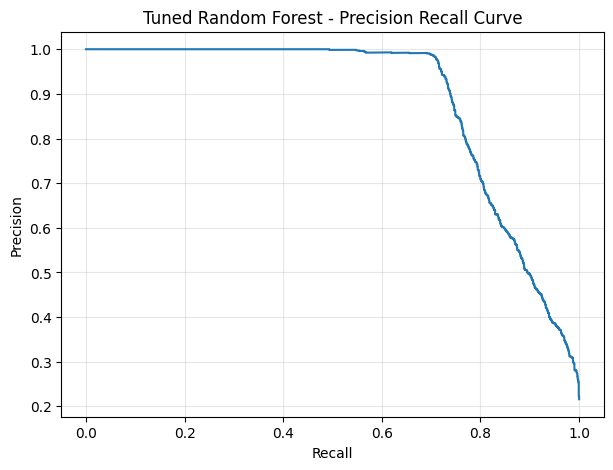

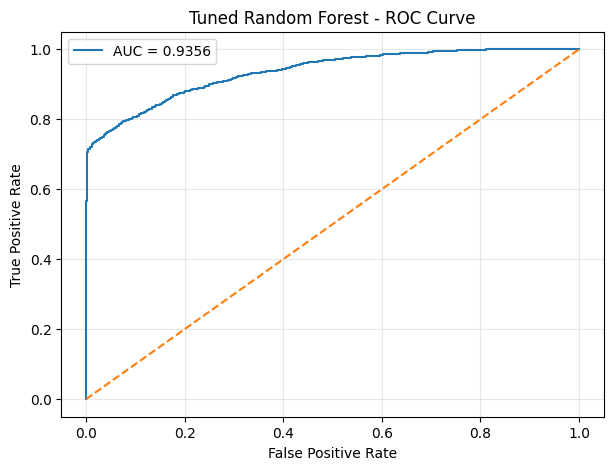

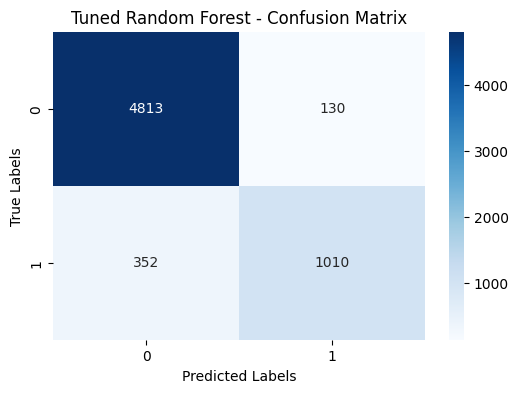

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.97      0.95      4943
           1       0.89      0.74      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.91      0.86      0.88      6305
weighted avg       0.92      0.92      0.92      6305



{'Accuracy': 0.92355273592387,
 'Precision': 0.8859649122807017,
 'Recall': 0.7415565345080763,
 'F1 Score': 0.8073541167066347,
 'ROC AUC': np.float64(0.9355970842939912),
 'Confusion Matrix': array([[4813,  130],
        [ 352, 1010]])}

In [69]:
print("Fitting Random Forest...")
rf_random_search.fit(X_train, y_train)
print("Random Forest search complete.")

print("Evaluating Best Random Forest Model:")
evaluate_model("Tuned Random Forest", rf_random_search.best_estimator_, X_test, y_test)

Fitting AdaBoost...
Fitting 5 folds for each of 50 candidates, totalling 250 fits
AdaBoost search complete.
Evaluating Best AdaBoost Model:
Tuned AdaBoost Metrics:
Accuracy: 0.8891
Precision: 0.8055
Recall: 0.6417
F1 Score: 0.7143
ROC AUC: 0.9032


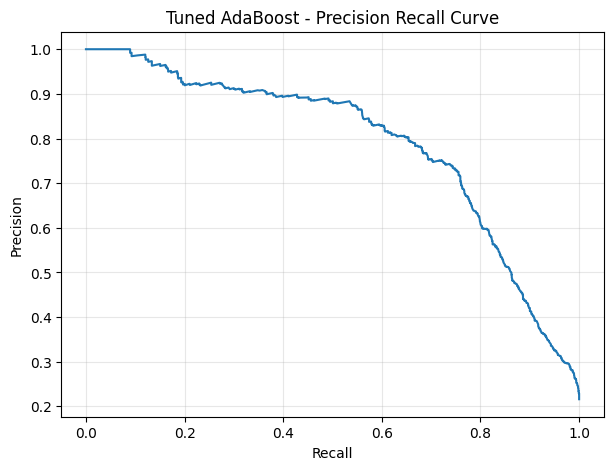

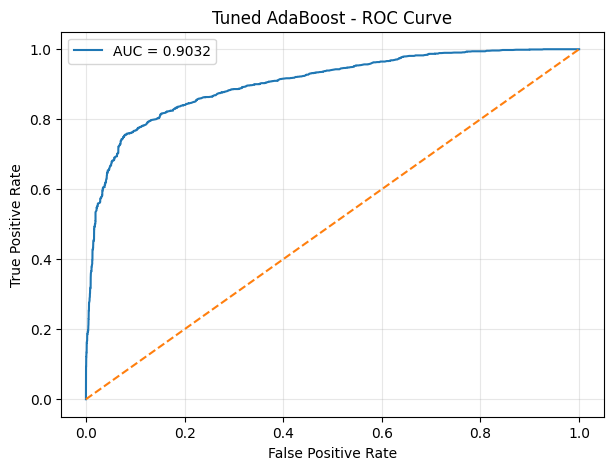

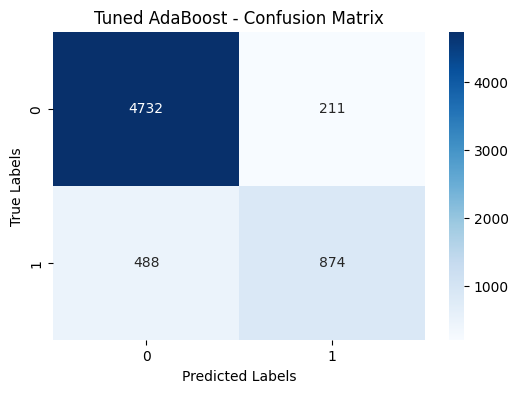

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.96      0.93      4943
           1       0.81      0.64      0.71      1362

    accuracy                           0.89      6305
   macro avg       0.86      0.80      0.82      6305
weighted avg       0.88      0.89      0.88      6305



{'Accuracy': 0.8891356066613798,
 'Precision': 0.8055299539170507,
 'Recall': 0.6417033773861968,
 'F1 Score': 0.7143440948099714,
 'ROC AUC': np.float64(0.9031503931901503),
 'Confusion Matrix': array([[4732,  211],
        [ 488,  874]])}

In [70]:
print("Fitting AdaBoost...")
ada_random_search.fit(X_train, y_train)
print("AdaBoost search complete.")

print("Evaluating Best AdaBoost Model:")
evaluate_model("Tuned AdaBoost", ada_random_search.best_estimator_, X_test, y_test)

In [71]:
print("hyper paramtered xg model outcome:")
print("Best Params:", random_search.best_params_)
print("Best Score (ROC AUC):", random_search.best_score_)
print("Best Estimator:", random_search.best_estimator_)
print()

print("hyper paramtered randomforest model outcome:")
print("Best Params:", rf_random_search.best_params_)
print("Best Score (ROC AUC):", rf_random_search.best_score_)
print("Best Estimator:", rf_random_search.best_estimator_)
print()

print("hyper paramtered adaboost model outcome:")
print("Best Params:", ada_random_search.best_params_)
print("Best Score (ROC AUC):", ada_random_search.best_score_)
print("Best Estimator:", ada_random_search.best_estimator_)

hyper paramtered xg model outcome:
Best Params: {'classifier__colsample_bytree': np.float64(0.5248708096267587), 'classifier__gamma': np.float64(2.95633685837714), 'classifier__learning_rate': np.float64(0.0616921873168326), 'classifier__max_depth': 6, 'classifier__min_child_weight': 4, 'classifier__n_estimators': 435, 'classifier__subsample': np.float64(0.5766560517837737)}
Best Score (ROC AUC): 0.9459728211841959
Best Estimator: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                        

In [72]:
# # 1. Get the probability of class 1 from the fitted best XGBoost estimator
# # We use the entire X_test to calculate precision, recall, and thresholds accurately
# prob = random_search.predict_proba(X_test)

# # 2. For each threshold calculate precision and recall
# precisions, recalls, thresholds = precision_recall_curve(y_test, prob[:, 1])

# # 3. Calculate f1-score for each threshold
# # Using small epsilon to prevent division by zero
# f1 = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)

# # 4. Get the index and value of the threshold that produces the highest F1 score
# best_idx = np.argmax(f1)
# best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5
# print(f"Optimal Threshold: {best_threshold:.4f} with Best F1 Score: {f1[best_idx]:.4f}")

# # 5. Evaluate XGBoost model using the optimal threshold
# evaluate_model("Optimized XGBoost", random_search, X_test, y_test, threshold=best_threshold)

Probability caliberation
####the actual andd predicted probability must be same- linear line then -> good caliberated model
####if it is dofferent then poorly caliberated model
####methods to fix this poorly calierated model -
#### Platt scaling / Sigmoid   -> adjust the probabilities using sigmoid curve
####Tsotonic regression
####Temperature scaling- adjusting confidence of neural network predictions using one temp


In [94]:
#the actual andd predicted probability must be same- linear line then -> good caliberated model
#if it is dofferent then poorly caliberated model
#methods to fix this poorly calierated model -
# Platt scaling / Sigmoid   -> adjust the probabilities using sigmoid curve
#Tsotonic regression
#Temperature scaling- adjusting confidence of neural network predictions using one temp

#steps ---- >   caliberate xg model -> get probabilies -> create calibertaion curve -> plot



from sklearn.calibration import CalibratedClassifierCV, calibration_curve
caliberated_model = CalibratedClassifierCV(random_search.best_estimator_, cv=cv, method='sigmoid')
caliberated_model.fit(X_train, y_train)

CalibratedClassifierCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer())]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pi...
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.0616921873168326),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=6,
                                                                max_leaves=None,
                                                                min_child_weight=4,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=435,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]))

In [95]:
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve
import numpy as np

# 1. Obtain out-of-fold probability predictions on the training set for the calibrated model
# The test set is not used for threshold selection. However, this is not fully nested CV:
# hyperparameters were selected earlier using all of X_train.
calibrated_oof_probs = cross_val_predict(
    caliberated_model,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

# 2. Compute precision-recall curve on the out-of-fold predictions
precisions, recalls, thresholds = precision_recall_curve(y_train, calibrated_oof_probs)

# 3. Find threshold that yields the best F1 Score
# The final precision/recall values have no corresponding threshold
f1_scores = (
    2 * precisions[:-1] * recalls[:-1]
    / (precisions[:-1] + recalls[:-1] + 1e-9)
)

best_idx = np.argmax(f1_scores)
best_calibrated_threshold = thresholds[best_idx]

print("Optimal Calibrated Threshold:", best_calibrated_threshold)
print("Best OOF F1 Score:", f1_scores[best_idx])

Optimal Calibrated Threshold: 0.5832614404122295
Best OOF F1 Score: 0.8295918362408794


In [105]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix

# 4. Evaluate the calibrated model using the optimal calibrated threshold on the clean test set
calibrated_test_probs = caliberated_model.predict_proba(X_test)[:, 1]
y_test_pred_cal = (calibrated_test_probs >= best_calibrated_threshold).astype(int)

print("FINAL CALIBRATED MODEL TEST RESULTS:")
print("--------------------------------------------------")
print(f"Accuracy: {accuracy_score(y_test, y_test_pred_cal):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred_cal):.4f}")
print(f"Recall: {recall_score(y_test, y_test_pred_cal):.4f}")
print(f"F1 Score: {f1_score(y_test, y_test_pred_cal):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, calibrated_test_probs):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_cal))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_cal))

FINAL CALIBRATED MODEL TEST RESULTS:
--------------------------------------------------
Accuracy: 0.9351
Precision: 0.9360
Recall: 0.7511
F1 Score: 0.8334
ROC-AUC: 0.9517

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      4943
           1       0.94      0.75      0.83      1362

    accuracy                           0.94      6305
   macro avg       0.94      0.87      0.90      6305
weighted avg       0.94      0.94      0.93      6305


Confusion Matrix:
[[4873   70]
 [ 339 1023]]


In [106]:
# 5. Align Error Analysis with our Final Decision Rule
result_df_cal = X_test.copy()
result_df_cal['actual'] = y_test
result_df_cal['predicted'] = y_test_pred_cal

fp_df = result_df_cal[(result_df_cal['actual'] == 0) & (result_df_cal['predicted'] == 1)]
fn_df = result_df_cal[(result_df_cal['actual'] == 1) & (result_df_cal['predicted'] == 0)]

print(f"Number of False Positives: {len(fp_df)}")
print(f"Number of False Negatives: {len(fn_df)}")

Number of False Positives: 70
Number of False Negatives: 339


In [107]:
#2
uncaliberated = random_search.best_estimator_.predict_proba(X_test)[:, 1]
caliberated = caliberated_model.predict_proba(X_test)[:, 1]
caliberated

array([0.63893676, 0.02756305, 0.94969886, ..., 0.53004208, 0.02518164,
       0.01315466], shape=(6305,))

In [108]:
uncaliberated

array([0.77749443, 0.0621145 , 0.9924648 , ..., 0.5916715 , 0.06096852,
       0.00754526], shape=(6305,), dtype=float32)

In [109]:
#3. caliberation curve
actual_uncal,predicted_uncal = calibration_curve(y_test, uncaliberated,n_bins=10)
actual_cal,predicted_cal = calibration_curve(y_test, caliberated,n_bins=10)

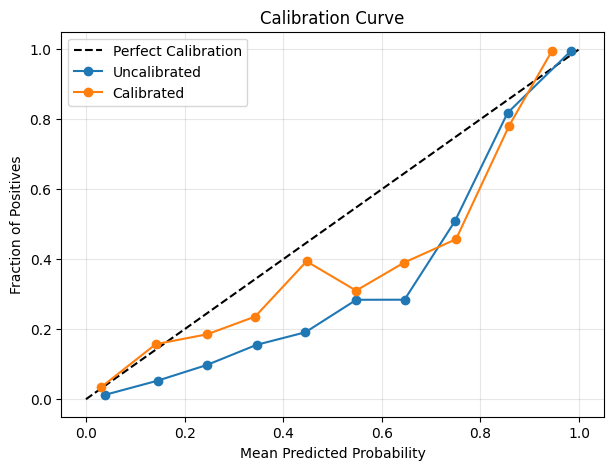

In [110]:
plt.figure(figsize=(7, 5))

plt.plot(
    [0, 1], [0, 1],
    linestyle='--',
    color='black',
    label='Perfect Calibration'
)

plt.plot(
    predicted_uncal, actual_uncal,
    marker='o',
    label='Uncalibrated'
)

plt.plot(
    predicted_cal, actual_cal,
    marker='o',
    label='Calibrated'
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Calibration Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#SHAP INNTERPRETATION - LOCAL AND GLOBAL
telling which features contributes how much in getting the output
##SHAP helps in understanding why the model makes this decison

In [111]:
!pip install shap

In [112]:
import shap
#2
preprocessor = random_search.best_estimator_.named_steps['preprocessor']
classifier = random_search.best_estimator_.named_steps['classifier']
X_test_transformed = preprocessor.transform(X_test)

# 3. Get the exact feature names generated after One-Hot Encoding
encoded_feature_names = preprocessor.get_feature_names_out()

#4
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns=encoded_feature_names)

# 5. Create the SHAP explainer (using TreeExplainer for XGBoost/Random Forest)
explainer = shap.TreeExplainer(classifier)

# 6. Calculate SHAP values for all rows in test set
shap_values = explainer(X_test_transformed)
shap_values

.values =
array([[-1.50832355e-01,  1.82878822e-02,  4.37578708e-01, ...,
        -1.12789208e-02,  1.51738944e-02,  1.29375402e-02],
       [-7.65437260e-02, -1.29124153e+00, -1.00723505e-01, ...,
        -1.14083476e-02,  3.61785572e-03, -3.24127008e-03],
       [ 6.56774268e-02,  4.01492739e+00,  2.32640821e-02, ...,
        -9.51949693e-03,  1.49885714e-02,  1.42064728e-02],
       ...,
       [ 5.67980949e-03,  5.94606698e-01,  1.29880071e-01, ...,
        -9.86706559e-03, -2.06039492e-02, -2.00660303e-02],
       [-6.38293549e-02, -1.30615854e+00,  4.76721041e-02, ...,
        -9.34012514e-03, -1.75796468e-02, -2.20493972e-02],
       [-3.05710942e-01, -1.28003561e+00, -4.41339947e-02, ...,
        -9.54608060e-03, -2.26865839e-02, -2.99447998e-02]],
      shape=(6305, 26), dtype=float32)

.base_values =
array([0.19899538, 0.19899538, 0.19899538, ..., 0.19899538, 0.19899538,
       0.19899538], shape=(6305,), dtype=float32)

.data =
array([[2.4000e+01, 3.0000e+04, 1.0000e+00, ...

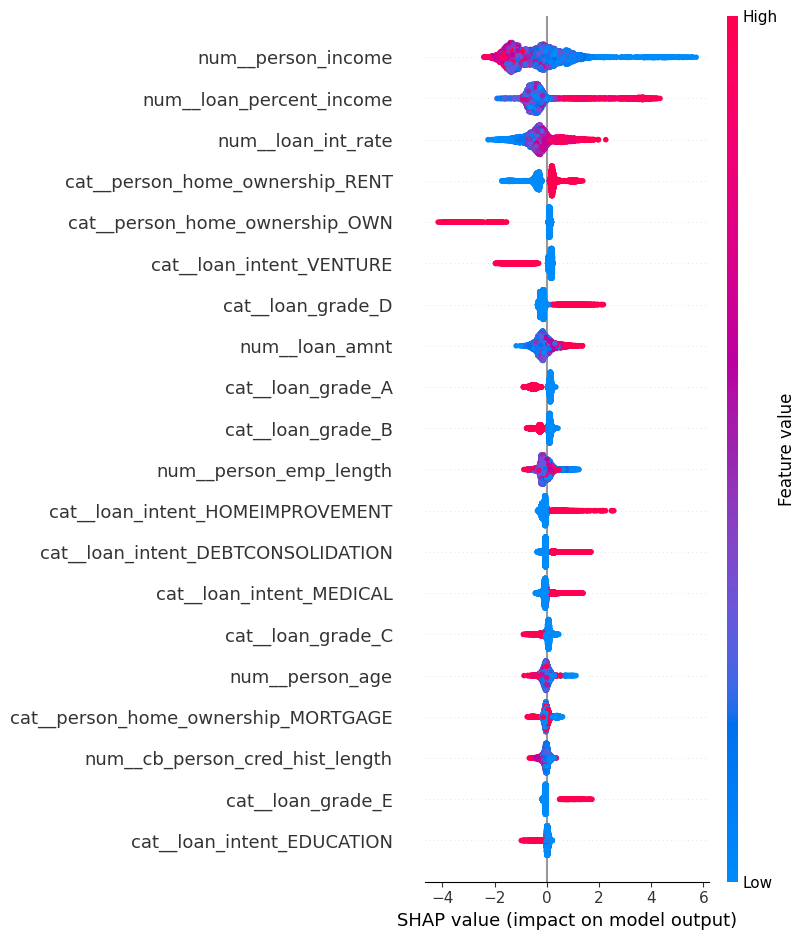

In [113]:
#GLOBAL EXPLAINANTIONS .... ABOVE WAS LOCAL ONE WHERE WE which features contribute to the output row by row.
# Here we are going to do it for overall datasets: which features matter the most for the whole dataset output?
shap.summary_plot(shap_values, X_test_transformed_df)

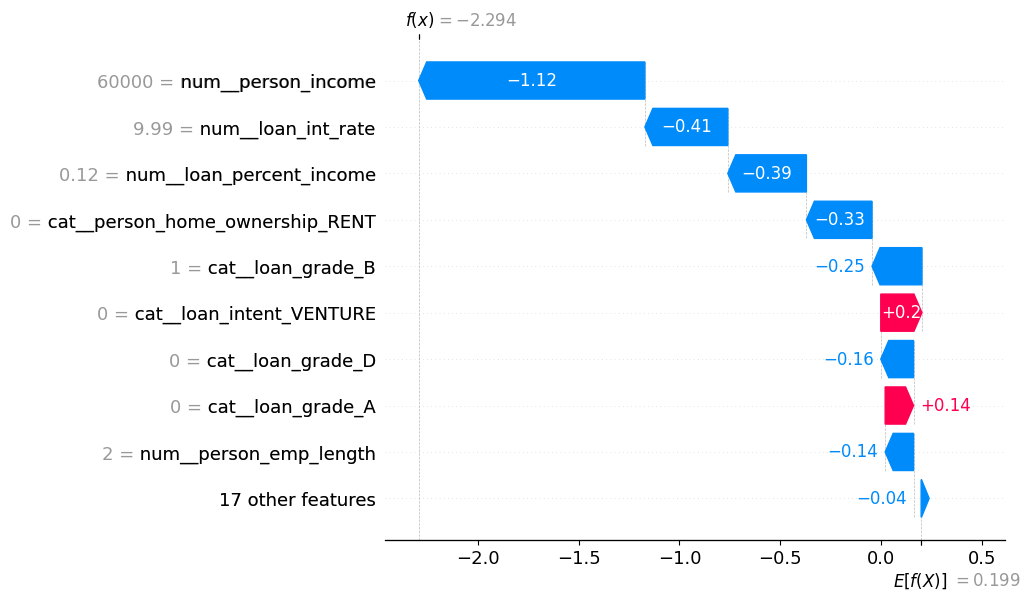

In [100]:
#LOCAL EXPLAINATIONS - choose row of idx 5
row_index=5

#drawing waterfall plot how each feature contributes up or down to outputs...
#Passing only the Explanation slice, which encapsulates base_values and data automatically.
shap.plots.waterfall(shap.Explanation(shap_values[row_index],feature_names=X_test_transformed_df.columns,base_values=explainer.expected_value,data=X_test_transformed[row_index]))
#

#analysing false positive and false positive


In [114]:
y_pred = y_test_pred_cal

# Construct the evaluation DataFrame using only the test dataset rows to match lengths
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred


result_df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
14455,24,30000,OWN,1.0,MEDICAL,E,15000,15.68,0.50,N,3,1,1
8701,23,60000,MORTGAGE,6.0,EDUCATION,C,25600,NaN,0.43,N,4,0,0
19804,29,18000,RENT,2.0,EDUCATION,C,3600,15.27,0.20,N,6,1,1
27252,32,130000,MORTGAGE,7.0,MEDICAL,B,13000,12.69,0.10,N,8,0,0
5610,23,45288,MORTGAGE,7.0,DEBTCONSOLIDATION,B,20500,9.25,0.45,N,2,0,0


In [115]:
#false positive- actual was 0 but predicted 1
false_positive = result_df[(result_df['actual'] == 0) & (result_df['predicted'] == 1)]
#false negative - actual was 1 but predicted 0
false_negative = result_df[(result_df['actual'] == 1) & (result_df['predicted'] == 0)]

In [116]:
false_positive=len(false_positive)
false_negative=len(false_negative)
print(f"Number of False Positives: {false_positive}")
print(f"Number of False Negatives: {false_negative}")

Number of False Positives: 70
Number of False Negatives: 339


NOW STORE THE MODEL

In [118]:
import joblib

joblib.dump(random_search.best_estimator_, 'xgboost_tuned_model.joblib')
joblib.dump(caliberated_model, 'credit_risk_model.joblib')
joblib.dump(best_calibrated_threshold, 'best_threshold.pkl')

joblib.dump(rf_random_search.best_estimator_, 'random_forest_tuned_model.joblib')
joblib.dump(ada_random_search.best_estimator_, 'adaboost_tuned_model.joblib')

print("Tuned models successfully saved to disk!")

Tuned models successfully saved to disk!
